# Logisitic regression

Let's create a very simple dataset with one indpendent variable and one dependent variable

In [ ]:
import numpy as np
import pandas as pd

import statsmodels.formula.api as smf
import statsmodels.api as sm

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

In [42]:
# 1. Create a dummy dataset
data = {
    'Hours_Studied': [1.0, 1.5, 1.8, 2.0, 2.3, 2.5, 2.8, 3.0, 3.1, 3.5, 4.0, 4.2, 4.5, 4.8, 5.0],
    'Passed':        [  0,   0,   0,   1,   0,   1,   0,   1,   0,   1,   1,   1,   1,   1,   1]
}

data = pd.DataFrame(data)
print(data)


    Hours_Studied  Passed
0             1.0       0
1             1.5       0
2             1.8       0
3             2.0       1
4             2.3       0
5             2.5       1
6             2.8       0
7             3.0       1
8             3.1       0
9             3.5       1
10            4.0       1
11            4.2       1
12            4.5       1
13            4.8       1
14            5.0       1


In [43]:
# 2. Fit the model using a formula (Y ~ X1 + X2)
model = smf.logit("Passed ~ Hours_Studied", data=data)
results = model.fit()

# 3. View the detailed summary
print(results.summary())


Optimization terminated successfully.
         Current function value: 0.394182
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Passed   No. Observations:                   15
Model:                          Logit   Df Residuals:                       13
Method:                           MLE   Df Model:                            1
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.4143
Time:                        06:39:57   Log-Likelihood:                -5.9127
converged:                       True   LL-Null:                       -10.095
Covariance Type:            nonrobust   LLR p-value:                  0.003825
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.9782      2.689     -1.851      0.064     -10.249       0.292
Hours_Studied     1.



Decision boundary is located at - beta_0 / beta_1:  2.6199244599906772


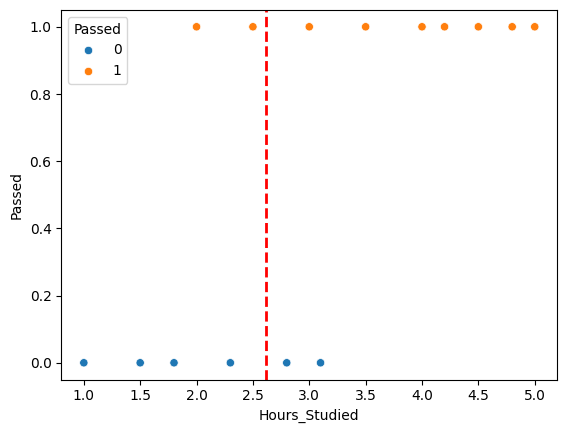

In [44]:
# 4. Plot the model and data
location =  -results.params.Intercept / results.params.Hours_Studied
print('\n\nDecision boundary is located at - beta_0 / beta_1: ',location)

# main plot
g = sns.scatterplot(data=data, x='Hours_Studied', y='Passed', hue='Passed')
# vertical line at decision boundary
plt.axvline(x=location, color='red', linestyle='--', linewidth=2)
plt.show()

# Multiple logistic regression
(still simple, just 2 independent variables)

The Palmer Penguins dataset is one of my favorites for demonstrating all kinds of things about stats and modeling

In [46]:
# get data for Adelie penguins
all_penguins = sns.load_dataset('penguins')
penguins = ( all_penguins[ all_penguins['species'] == 'Adelie' ]
            .dropna()
            .reset_index(drop=True)
            .drop(columns=['species','island'])
)
penguins

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,Male
1,39.5,17.4,186.0,3800.0,Female
2,40.3,18.0,195.0,3250.0,Female
3,36.7,19.3,193.0,3450.0,Female
4,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...
141,36.6,18.4,184.0,3475.0,Female
142,36.0,17.8,195.0,3450.0,Female
143,37.8,18.1,193.0,3750.0,Male
144,36.0,17.1,187.0,3700.0,Female


## Scaling the data
Both logistic regression and linear regression are fundamentally just some matrix algebra $$y=\beta^t x $$
where both $\beta, x$ are column vectors. Some of the rows in $x$ (which are the independent variables of the regression) may have values that are wildly different from other rows.  If one of the rows has a value around of 10 and another one has value of 10 billion, then the total vector lenth of $x$ is going to be absolutely dominated by the large magnitude variable.  

If this isn't just one datapoint, but all the dataponts, then that means the parameters $\beta$ we solve for will *also* be dominated by that large magnitude independent variable and the solution will not care much about the small magnitude variable.

Most of the time you will care about relationships in the small magnitude variables as well as the large magnitude variables. For example, a situation where you have variables of length in millimeters and weight in micrograms and you're describing people. Obviously there may also be times when these magnitude differences ARE what you want.  Like if the variables are micrograms of hydrogen, carbon, nitrogen, oxygen, etc and you're describing a chemical sample where it just so happens that there's very little of one of the elements in all the samples and lots of others.

To force the solution to care about variables equally we can rescale the raw data so that each variable has roughly the same order of magnitude. There are many choices of scalers, you can see some of them at https://scikit-learn.org/stable/modules/preprocessing.html#preprocessing$0

In [45]:
# Identify numeric columns
numeric_cols = penguins.select_dtypes(include=['float64', 'int64']).columns

# Initialize and apply StandardScaler to all the numeric columns
scaler = StandardScaler()
penguins_scaled = penguins.copy()
penguins_scaled[numeric_cols] = scaler.fit_transform(penguins[numeric_cols])

# Map 'sex' to 0 and 1 because statsmodels hates string encoded variables
penguins_scaled['sex'] = penguins_scaled['sex'].map({'Male': 1, 'Female': 0})

print(penguins_scaled)
print()
print(penguins_scaled.agg(['mean', 'std']))

     bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex
0          0.104025       0.290284          -1.400540     0.095911    1
1          0.254772      -0.779539          -0.631244     0.205309    0
2          0.556265      -0.285774           0.753488    -0.998069    0
3         -0.800453       0.784048           0.445770    -0.560477    0
4          0.179399       1.853870          -0.015807    -0.122885    1
..              ...            ...                ...          ...  ...
141       -0.838140       0.043402          -0.938962    -0.505778    0
142       -1.064259      -0.450362           0.753488    -0.560477    0
143       -0.385901      -0.203480           0.445770     0.095911    1
144       -1.064259      -1.026421          -0.477385    -0.013487    0
145        1.008504       0.125696           1.676643     0.642900    1

[146 rows x 5 columns]

      bill_length_mm  bill_depth_mm  flipper_length_mm   body_mass_g       sex
mean   -1.222766e-15   1.228850e

In [40]:
model = smf.logit("sex ~ flipper_length_mm + body_mass_g", data=penguins_scaled)
results = model.fit()
print(results.summary())

Optimization terminated successfully.
         Current function value: 0.303911
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                    sex   No. Observations:                  146
Model:                          Logit   Df Residuals:                      143
Method:                           MLE   Df Model:                            2
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.5615
Time:                        06:31:57   Log-Likelihood:                -44.371
converged:                       True   LL-Null:                       -101.20
Covariance Type:            nonrobust   LLR p-value:                 2.088e-25
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.2090      0.274      0.764      0.445      -0.327       0.745
flipper_

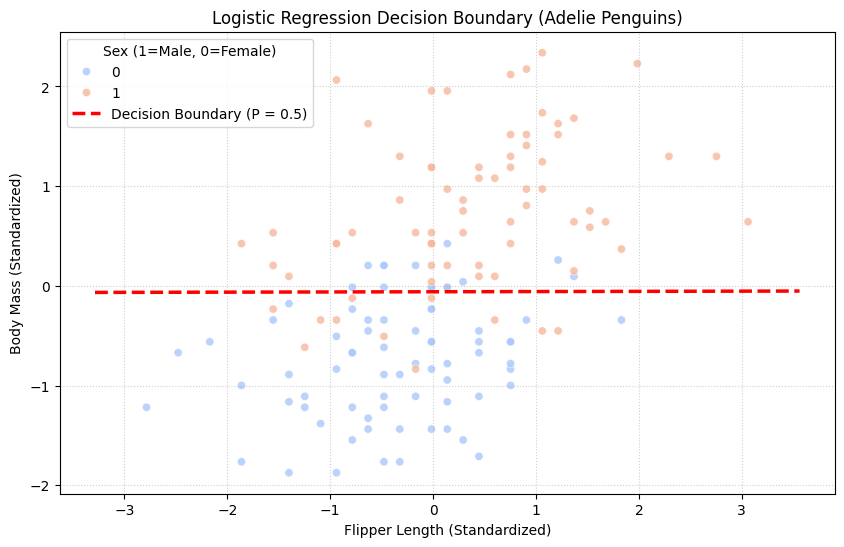

In [41]:
# Retrieve model coefficients
intercept = results.params['Intercept']
beta_flipper = results.params['flipper_length_mm']
beta_mass = results.params['body_mass_g']

# Create a range of values for flipper length to plot the line
x_values = np.linspace(penguins_scaled['flipper_length_mm'].min() - 0.5,
                          penguins_scaled['flipper_length_mm'].max() + 0.5, 100)

# Solve Intercept + beta_flipper * x + beta_mass * y = 0 for y
# y = -(Intercept + beta_flipper * x) / beta_mass
y_values = -(intercept + beta_flipper * x_values) / beta_mass

# Create the plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=penguins_scaled,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='sex',
    palette='coolwarm',
    alpha=0.8
)

plt.plot(x_values, y_values, color='red', linestyle='--', linewidth=2.5, label='Decision Boundary (P = 0.5)')

plt.title('Logistic Regression Decision Boundary (Adelie Penguins)')
plt.xlabel('Flipper Length (Standardized)')
plt.ylabel('Body Mass (Standardized)')
plt.legend(title='Sex (1=Male, 0=Female)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [49]:
female_penguins = all_penguins[ all_penguins['sex'] == 'Female' ]
female_penguins = (
    female_penguins
    .dropna()
    .reset_index(drop=True)
    .drop(columns=['sex','island'])
)

female_penguins[numeric_cols] = scaler.fit_transform(female_penguins[numeric_cols])
female_penguins['species'] = female_penguins['species'].map({'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2})
female_penguins



,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,0,-0.531230,0.544368,-0.911802,-0.093763
1,0,-0.367584,0.879521,-0.189655,-0.921889
2,0,-1.103992,1.605684,-0.350132,-0.620752
3,0,-0.653965,0.767803,-1.312994,-0.357258
4,0,-0.203938,0.656086,-1.232756,-0.997173
...,...,...,...,...,...
160,2,0.287001,-0.684523,1.254639,1.186068
161,2,0.839307,-1.298969,1.575593,0.772005
162,2,1.043865,-1.522404,1.334878,1.600131
163,2,0.962041,-1.187251,1.415116,1.487204


In [56]:
# Fit a multinomial logistic regression using the formula API
model_multi = smf.mnlogit("species ~  body_mass_g + flipper_length_mm", data=female_penguins)
results_multi = model_multi.fit()
print(results_multi.summary())

         Current function value: 0.361329
         Iterations: 35
                          MNLogit Regression Results                          
Dep. Variable:                species   No. Observations:                  165
Model:                        MNLogit   Df Residuals:                      159
Method:                           MLE   Df Model:                            4
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.6571
Time:                        07:10:15   Log-Likelihood:                -59.619
converged:                      False   LL-Null:                       -173.88
Covariance Type:            nonrobust   LLR p-value:                 2.759e-48
        species=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.6968      0.458      1.522      0.128      -0.200       1.594
body_mass_g           1.0324      0.582     

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:858: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mnfit = base.LikelihoodModel.fit(


Note that we have two tables now... because there are two regressions.  Logisitic regression is for binary choices.  Multinomial logistic regression is approximating a 3 (or more) category prediction by multiple binary logistic regressions.  So the first table is the prediction of Species=0 vs Species=1.  The 2nd table is the prediction of Species=0 vs SPecies=2.  Both produce probabilities of category membership.  

What if there's a conflict in the two regressions, and they disagree about the species of a particular datapoint?  If a particular datapoint is Species=1 in one regression and Species=2 in the other, then the final prediction is whichever species has the highest probability among the two choices.   

The warning and lack of convergence (converged: False) indicate a common issue in logistic regression called complete separation (or quasi-complete separation).

Why did this happen?
Looking at the coefficients for species=2 (Gentoo penguins), we see extremely large values: a coefficient of $51.5$ for flipper_length_mm and standard errors on the order of $10^4$.

This happens because, in our female dataset, the feature flipper_length_mm (and/or body_mass_g) can perfectly separate Gentoo penguins from the other species. When a feature perfectly separates a class, the Maximum Likelihood Estimation (MLE) process tries to push the coefficient to infinity to achieve a probability of exactly $1$$1$ or $0$$0$. The optimization solver keeps iterating until it hits its maximum limit (35 iterations here) and fails to converge, leading to astronomical standard errors and invalid p-values for that class.

OK, here's a stupid idea.  What if we use scikit-learn (a machine learning focussed library) instead of statsmodels (a statistical modeling focussed library)

In [58]:
from sklearn.linear_model import LogisticRegression

# Prepare features and target
X = female_penguins[['body_mass_g', 'flipper_length_mm']]
y = female_penguins['species']

# Initialize Logistic Regression for multiclass classification
# 'multinomial' is set explicitly, and we can adjust C to control regularization
lr_model = LogisticRegression()
lr_model.fit(X, y)

# Display coefficients and intercept
print("Classes:", lr_model.classes_)
print("Intercepts:", lr_model.intercept_)
print("Coefficients:\n", lr_model.coef_)
print("Model accuracy:", lr_model.score(X, y))

Classes: [0 1 2]
Intercepts: [ 0.25427011  0.56518471 -0.81945482]
Coefficients:
 [[-1.24374977 -1.51420088]
 [-0.4977758  -0.49343156]
 [ 1.74152558  2.00763245]]
Model accuracy: 0.8242424242424242


Why did scikit-learn converge while statsmodels failed?
By default, scikit-learn's LogisticRegression applies L2 regularization (defaulting to the parameter C=1.0). This regularization penalizes extremely large coefficients, keeping them bounded. **Regularization** is a way to implement a penalty on a complex model form, and force the model to be more biased, more simple.  We will study regularization properly in a few weeks, if you want to 

In statsmodels, logistic regression was performed without regularization, allowing coefficients to run off to large values because the two classes were TOO EASY to separate.

And this is a **FUNDAMENTAL DIFFERENCE** between sklearn and statsmodels.  A statistician doesn't want any model compnents they didn't ask for.  They are experts building models that reflect the causality they are hypothesizing, and they want a report on the likelihood of their hypothesis.  If a statistician wants regularization in the model they know enough to include it.

OTOH, a machine learning engineer just wants a good prediction and doesn't mind if some choices are made behind the scenes that they aren't aware of.  They are not forming a hypothesis of causality, they just want good predictions.  ML engineers don't need a report on the likelihood and may not even know what to do with one since they aren't expert statisticians.

Unsuprisingly, statsmodels WILL apply regularization (of the L1 sort, not L2!) if you want it to.  

In [60]:
# Define the multinomial model using formula API
model_regularized = smf.mnlogit("species ~ body_mass_g + flipper_length_mm", data=female_penguins)

# Fit with L2 regularization by setting method='l1' and L1_wt=0.0 (pure L2)
# 'alpha' controls the strength of regularization
results_regularized = model_regularized.fit_regularized(method='l1', alpha=1.0, L1_wt=0.0)

print(results_regularized.summary())

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.444514075980874
            Iterations: 54
            Function evaluations: 54
            Gradient evaluations: 54
                          MNLogit Regression Results                          
Dep. Variable:                species   No. Observations:                  165
Model:                        MNLogit   Df Residuals:                      159
Method:                           MLE   Df Model:                            4
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.6332
Time:                        07:19:47   Log-Likelihood:                -63.785
converged:                       True   LL-Null:                       -173.88
Covariance Type:            nonrobust   LLR p-value:                 1.714e-46
        species=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------

In [61]:
# Calculate predicted probabilities for each of the 3 classes
pred_probs = results_regularized.predict(female_penguins)

# The predicted class is the one with the highest probability
predicted_classes = pred_probs.idxmax(axis=1)

# Calculate accuracy compared to the actual target labels
actual_classes = female_penguins['species']
accuracy = (predicted_classes == actual_classes).mean()

print(f"Regularized Statsmodels Model Accuracy: {accuracy:.4%}")

# Generate a classification report or a simple confusion matrix for more insight
from sklearn.metrics import classification_report, confusion_matrix
print("\nConfusion Matrix:")
print(confusion_matrix(actual_classes, predicted_classes))
print("\nClassification Report:")
print(classification_report(actual_classes, predicted_classes, target_names=['Adelie (0)', 'Chinstrap (1)', 'Gentoo (2)']))

Regularized Statsmodels Model Accuracy: 81.2121%

Confusion Matrix:
[[70  3  0]
 [28  6  0]
 [ 0  0 58]]

Classification Report:
               precision    recall  f1-score   support

   Adelie (0)       0.71      0.96      0.82        73
Chinstrap (1)       0.67      0.18      0.28        34
   Gentoo (2)       1.00      1.00      1.00        58

     accuracy                           0.81       165
    macro avg       0.79      0.71      0.70       165
 weighted avg       0.80      0.81      0.77       165



# LDA

Statsmodels does not implement LDA, but sklearn does.  

With LDA, each class you're predicting is described by its own Gaussian mean with a covariance structure shared between all classes

In [62]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import classification_report, confusion_matrix

# Prepare features (X) and target (y)
X = female_penguins[['body_mass_g', 'flipper_length_mm']]
y = female_penguins['species']

# Initialize and fit the LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

# Make predictions
lda_predictions = lda.predict(X)

# Calculate accuracy
lda_accuracy = lda.score(X, y)
print(f"LDA Model Accuracy: {lda_accuracy:.4%}")

# Display Confusion Matrix & Classification Report
print("\nConfusion Matrix:")
print(confusion_matrix(y, lda_predictions))
print("\nClassification Report:")
print(classification_report(y, lda_predictions, target_names=['Adelie (0)', 'Chinstrap (1)', 'Gentoo (2)']))

LDA Model Accuracy: 84.8485%

Confusion Matrix:
[[69  4  0]
 [21 13  0]
 [ 0  0 58]]

Classification Report:
               precision    recall  f1-score   support

   Adelie (0)       0.77      0.95      0.85        73
Chinstrap (1)       0.76      0.38      0.51        34
   Gentoo (2)       1.00      1.00      1.00        58

     accuracy                           0.85       165
    macro avg       0.84      0.78      0.79       165
 weighted avg       0.85      0.85      0.83       165



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearDiscriminantAnalysis was fitted with feature names
  warnings.warn(


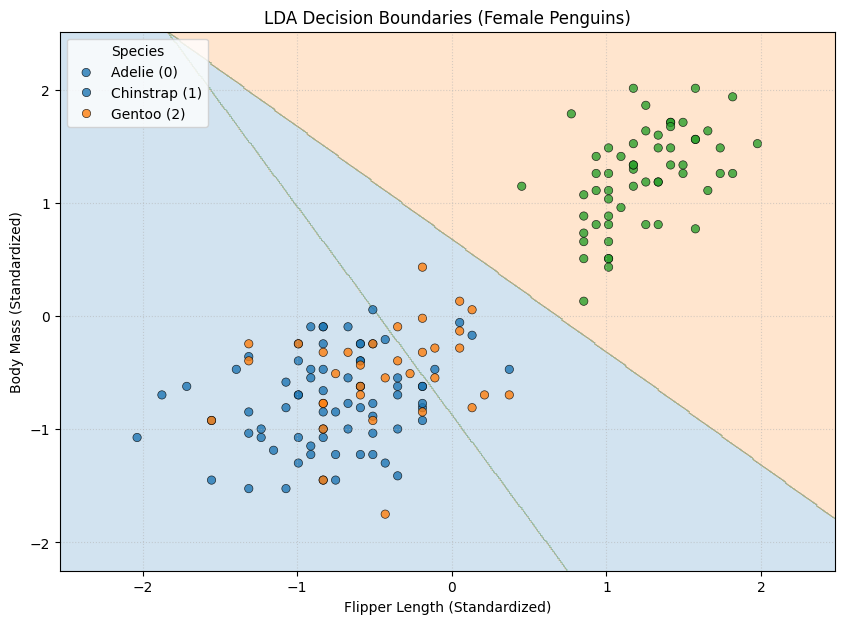

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the grid bounds based on our standardized features
x_min, x_max = X['flipper_length_mm'].min() - 0.5, X['flipper_length_mm'].max() + 0.5
y_min, y_max = X['body_mass_g'].min() - 0.5, X['body_mass_g'].max() + 0.5

# Generate mesh grid points
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Predict classifications over the grid using flipper_length_mm (x) and body_mass_g (y)
# Note: our X features were defined as ['body_mass_g', 'flipper_length_mm']
grid_points = np.c_[yy.ravel(), xx.ravel()]
Z = lda.predict(grid_points)
Z = Z.reshape(xx.shape)

# Plot setup
plt.figure(figsize=(10, 7))

# Plot decision regions
plt.contourf(xx, yy, Z, alpha=0.2, colors=['#1f77b4', '#ff7f0e', '#2ca02c'])

# Scatter plot of actual data points
sns.scatterplot(
    data=female_penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    edgecolor='k',
    alpha=0.8
)

plt.title("LDA Decision Boundaries (Female Penguins)")
plt.xlabel("Flipper Length (Standardized)")
plt.ylabel("Body Mass (Standardized)")
plt.legend(labels=['Adelie (0)', 'Chinstrap (1)', 'Gentoo (2)'], title="Species")
plt.grid(True, linestyle=':', alpha=0.5)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.show()

## K-Nearest Neighbors (KNN)

Now we will train a K-Nearest Neighbors classifier on the same standardized features. Since KNN is a non-parametric, distance-based model, we expect it to produce more flexible, non-linear decision boundaries than LDA and Multinomial Logistic Regression.

In [64]:
from sklearn.neighbors import KNeighborsClassifier

# Prepare features (X) and target (y)
X = female_penguins[['body_mass_g', 'flipper_length_mm']]
y = female_penguins['species']

# Initialize and fit KNN (let's use k=5 as a default starting point)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

# Make predictions
knn_predictions = knn.predict(X)

# Calculate accuracy
knn_accuracy = knn.score(X, y)
print(f"KNN Model Accuracy (k=5): {knn_accuracy:.4%}")

# Display Confusion Matrix & Classification Report
print("\nConfusion Matrix:")
print(confusion_matrix(y, knn_predictions))
print("\nClassification Report:")
print(classification_report(y, knn_predictions, target_names=['Adelie (0)', 'Chinstrap (1)', 'Gentoo (2)']))

KNN Model Accuracy (k=5): 85.4545%

Confusion Matrix:
[[69  4  0]
 [20 14  0]
 [ 0  0 58]]

Classification Report:
               precision    recall  f1-score   support

   Adelie (0)       0.78      0.95      0.85        73
Chinstrap (1)       0.78      0.41      0.54        34
   Gentoo (2)       1.00      1.00      1.00        58

     accuracy                           0.85       165
    macro avg       0.85      0.79      0.80       165
 weighted avg       0.85      0.85      0.84       165



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


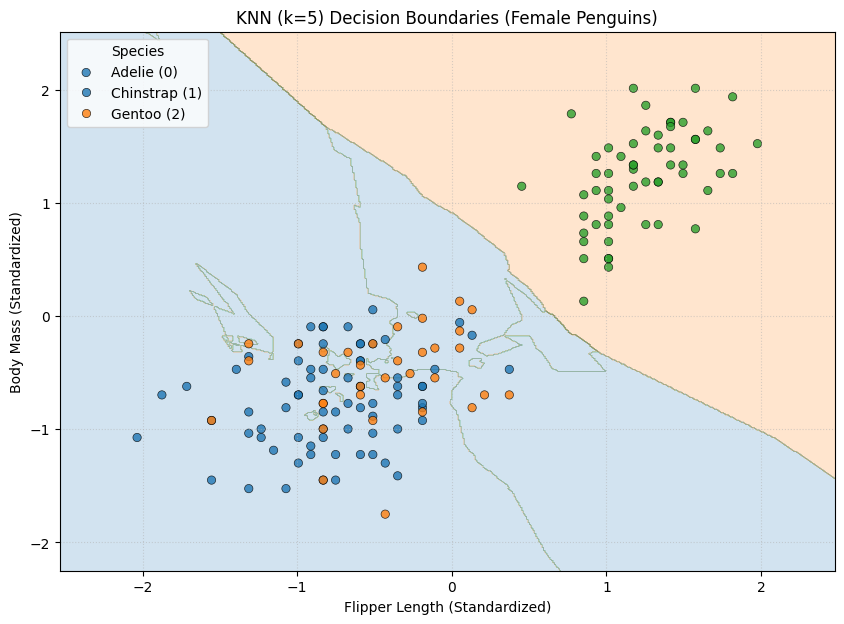

In [65]:
# Generate grid points for decision boundary visualization
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
grid_points = np.c_[yy.ravel(), xx.ravel()]

# Predict classifications over the grid using KNN
Z_knn = knn.predict(grid_points)
Z_knn = Z_knn.reshape(xx.shape)

# Plot setup
plt.figure(figsize=(10, 7))

# Plot KNN decision regions
plt.contourf(xx, yy, Z_knn, alpha=0.2, colors=['#1f77b4', '#ff7f0e', '#2ca02c'])

# Scatter plot of actual data points
sns.scatterplot(
    data=female_penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    palette=['#1f77b4', '#ff7f0e', '#2ca02c'],
    edgecolor='k',
    alpha=0.8
)

plt.title("KNN (k=5) Decision Boundaries (Female Penguins)")
plt.xlabel("Flipper Length (Standardized)")
plt.ylabel("Body Mass (Standardized)")
plt.legend(labels=['Adelie (0)', 'Chinstrap (1)', 'Gentoo (2)'], title="Species")
plt.grid(True, linestyle=':', alpha=0.5)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.show()

# Your turn

Try out different models on the penguins dataset and compare them.  